In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

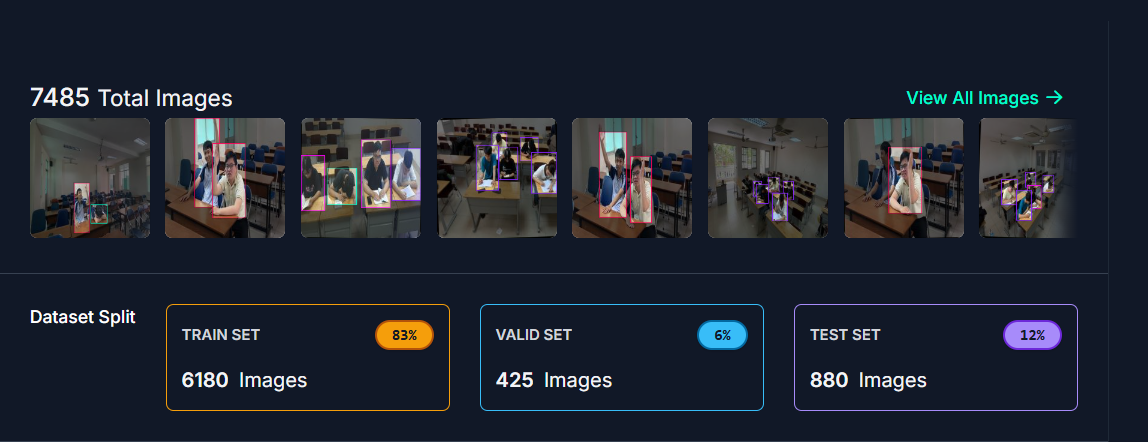

In [3]:
!pip -q install roboflow

In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key="jTRPGmwyXhhHPTZJjIia")
project = rf.workspace("mariotn689").project("classroom-coc8d")
version = project.version(24)
dataset = version.download("yolov8")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to classroom-24 in yolov8:: 100%|██████████| 14982/14982 [00:01<00:00, 7632.97it/s]


In [5]:
!pip -q install  ultralytics

# **Entraînement du modèle**

In [6]:
!yolo task=detect mode=train model='yolov8n.pt' data=/kaggle/working/classroom-24/data.yaml epochs=15 imgsz=704

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
100%|███████████████████████████████████████| 6.25M/6.25M [00:00<00:00, 101MB/s]
Ultralytics 8.3.49 🚀 Python-3.10.14 torch-2.4.0 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/working/classroom-24/data.yaml, epochs=15, time=None, patience=100, batch=16, imgsz=704, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0

# **Affichage des différentes métriques**

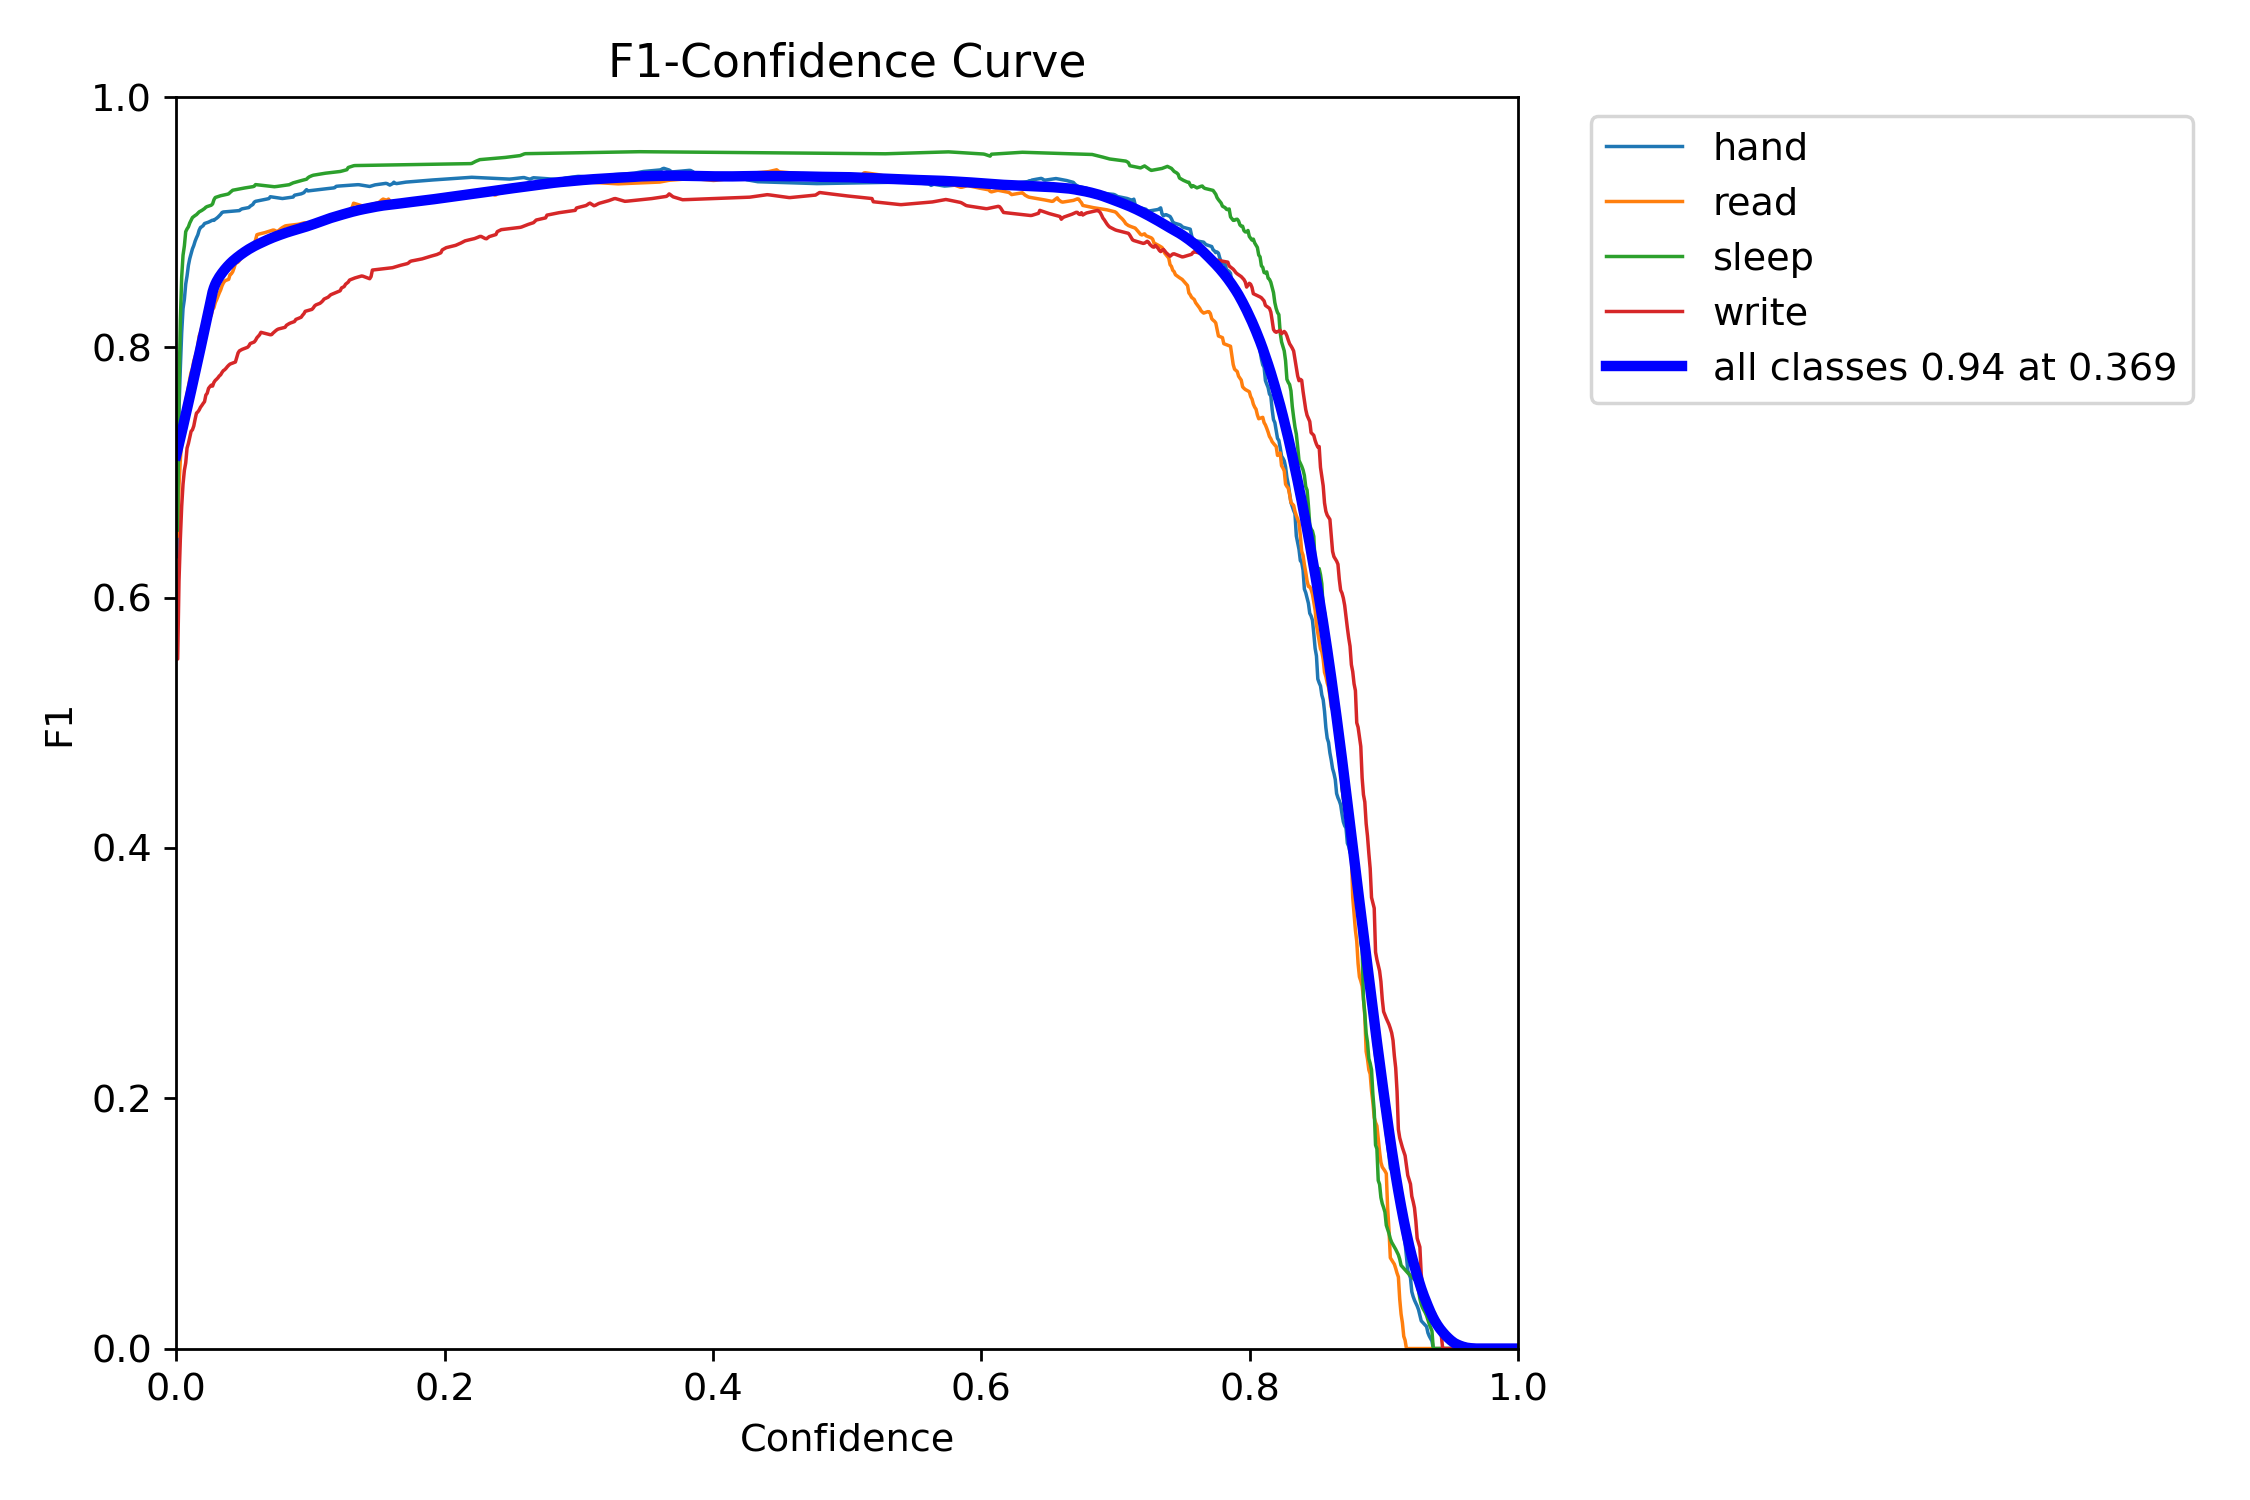

In [7]:
from IPython.display import display, Image
Image(filename='/kaggle/working/runs/detect/train/F1_curve.png', height=640)

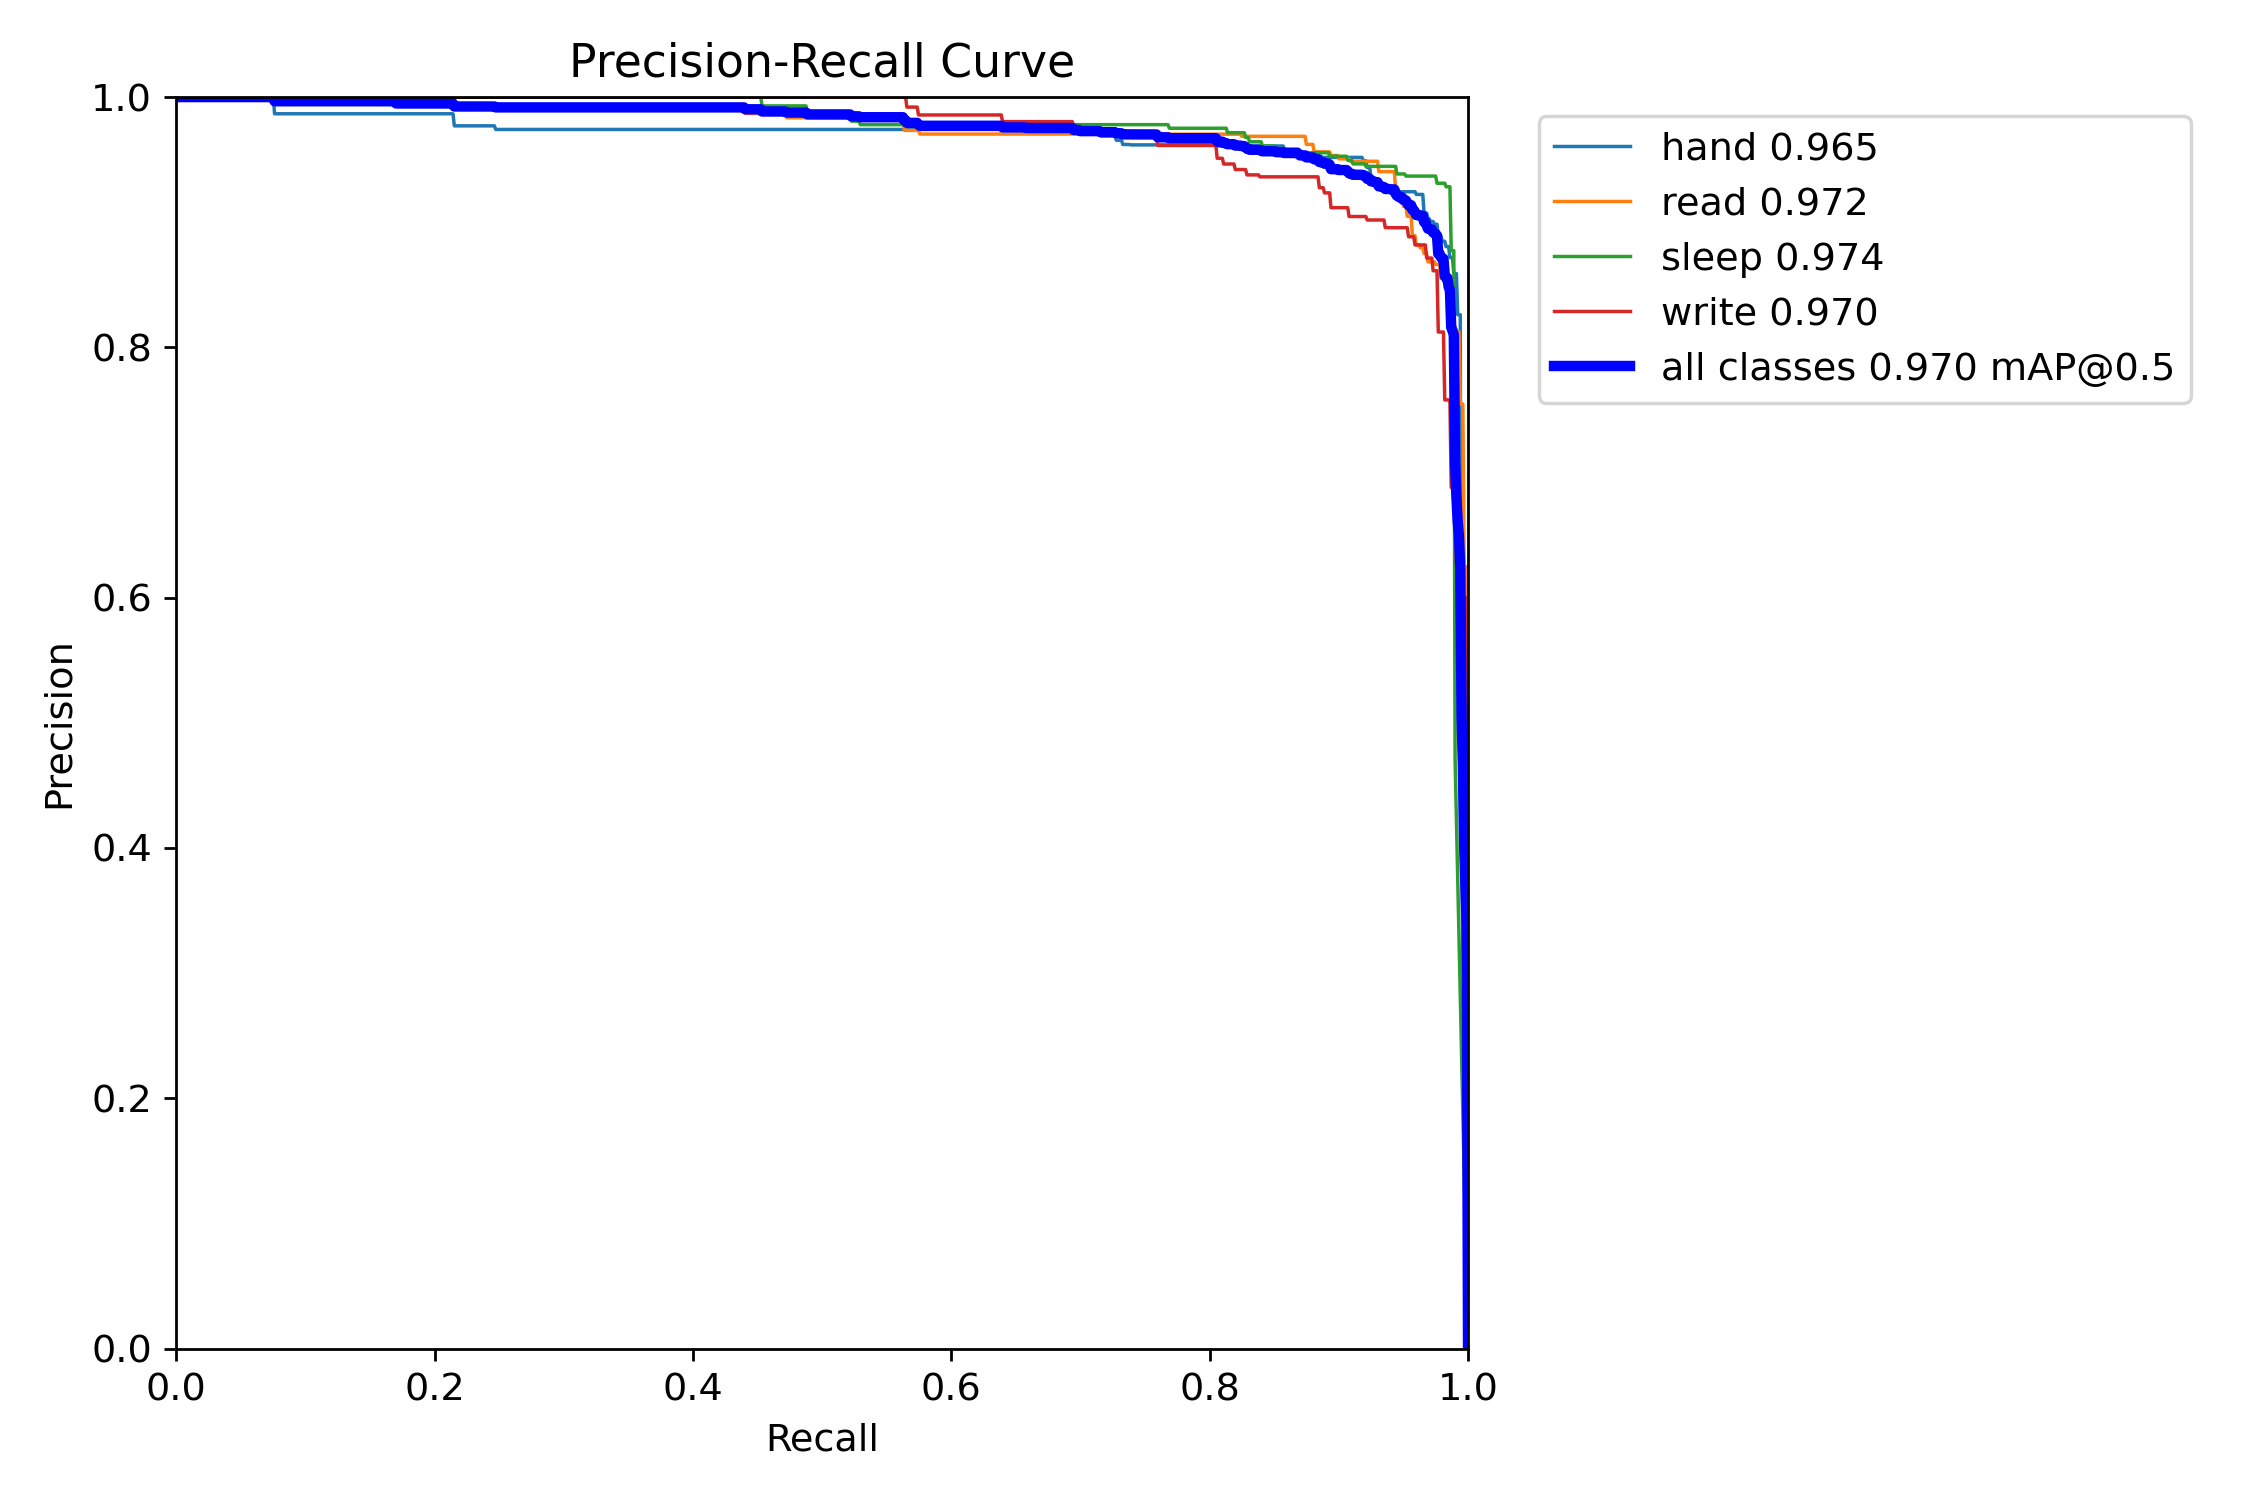

In [8]:
from IPython.display import display, Image
Image(filename='/kaggle/working/runs/detect/train/PR_curve.png', height=640)

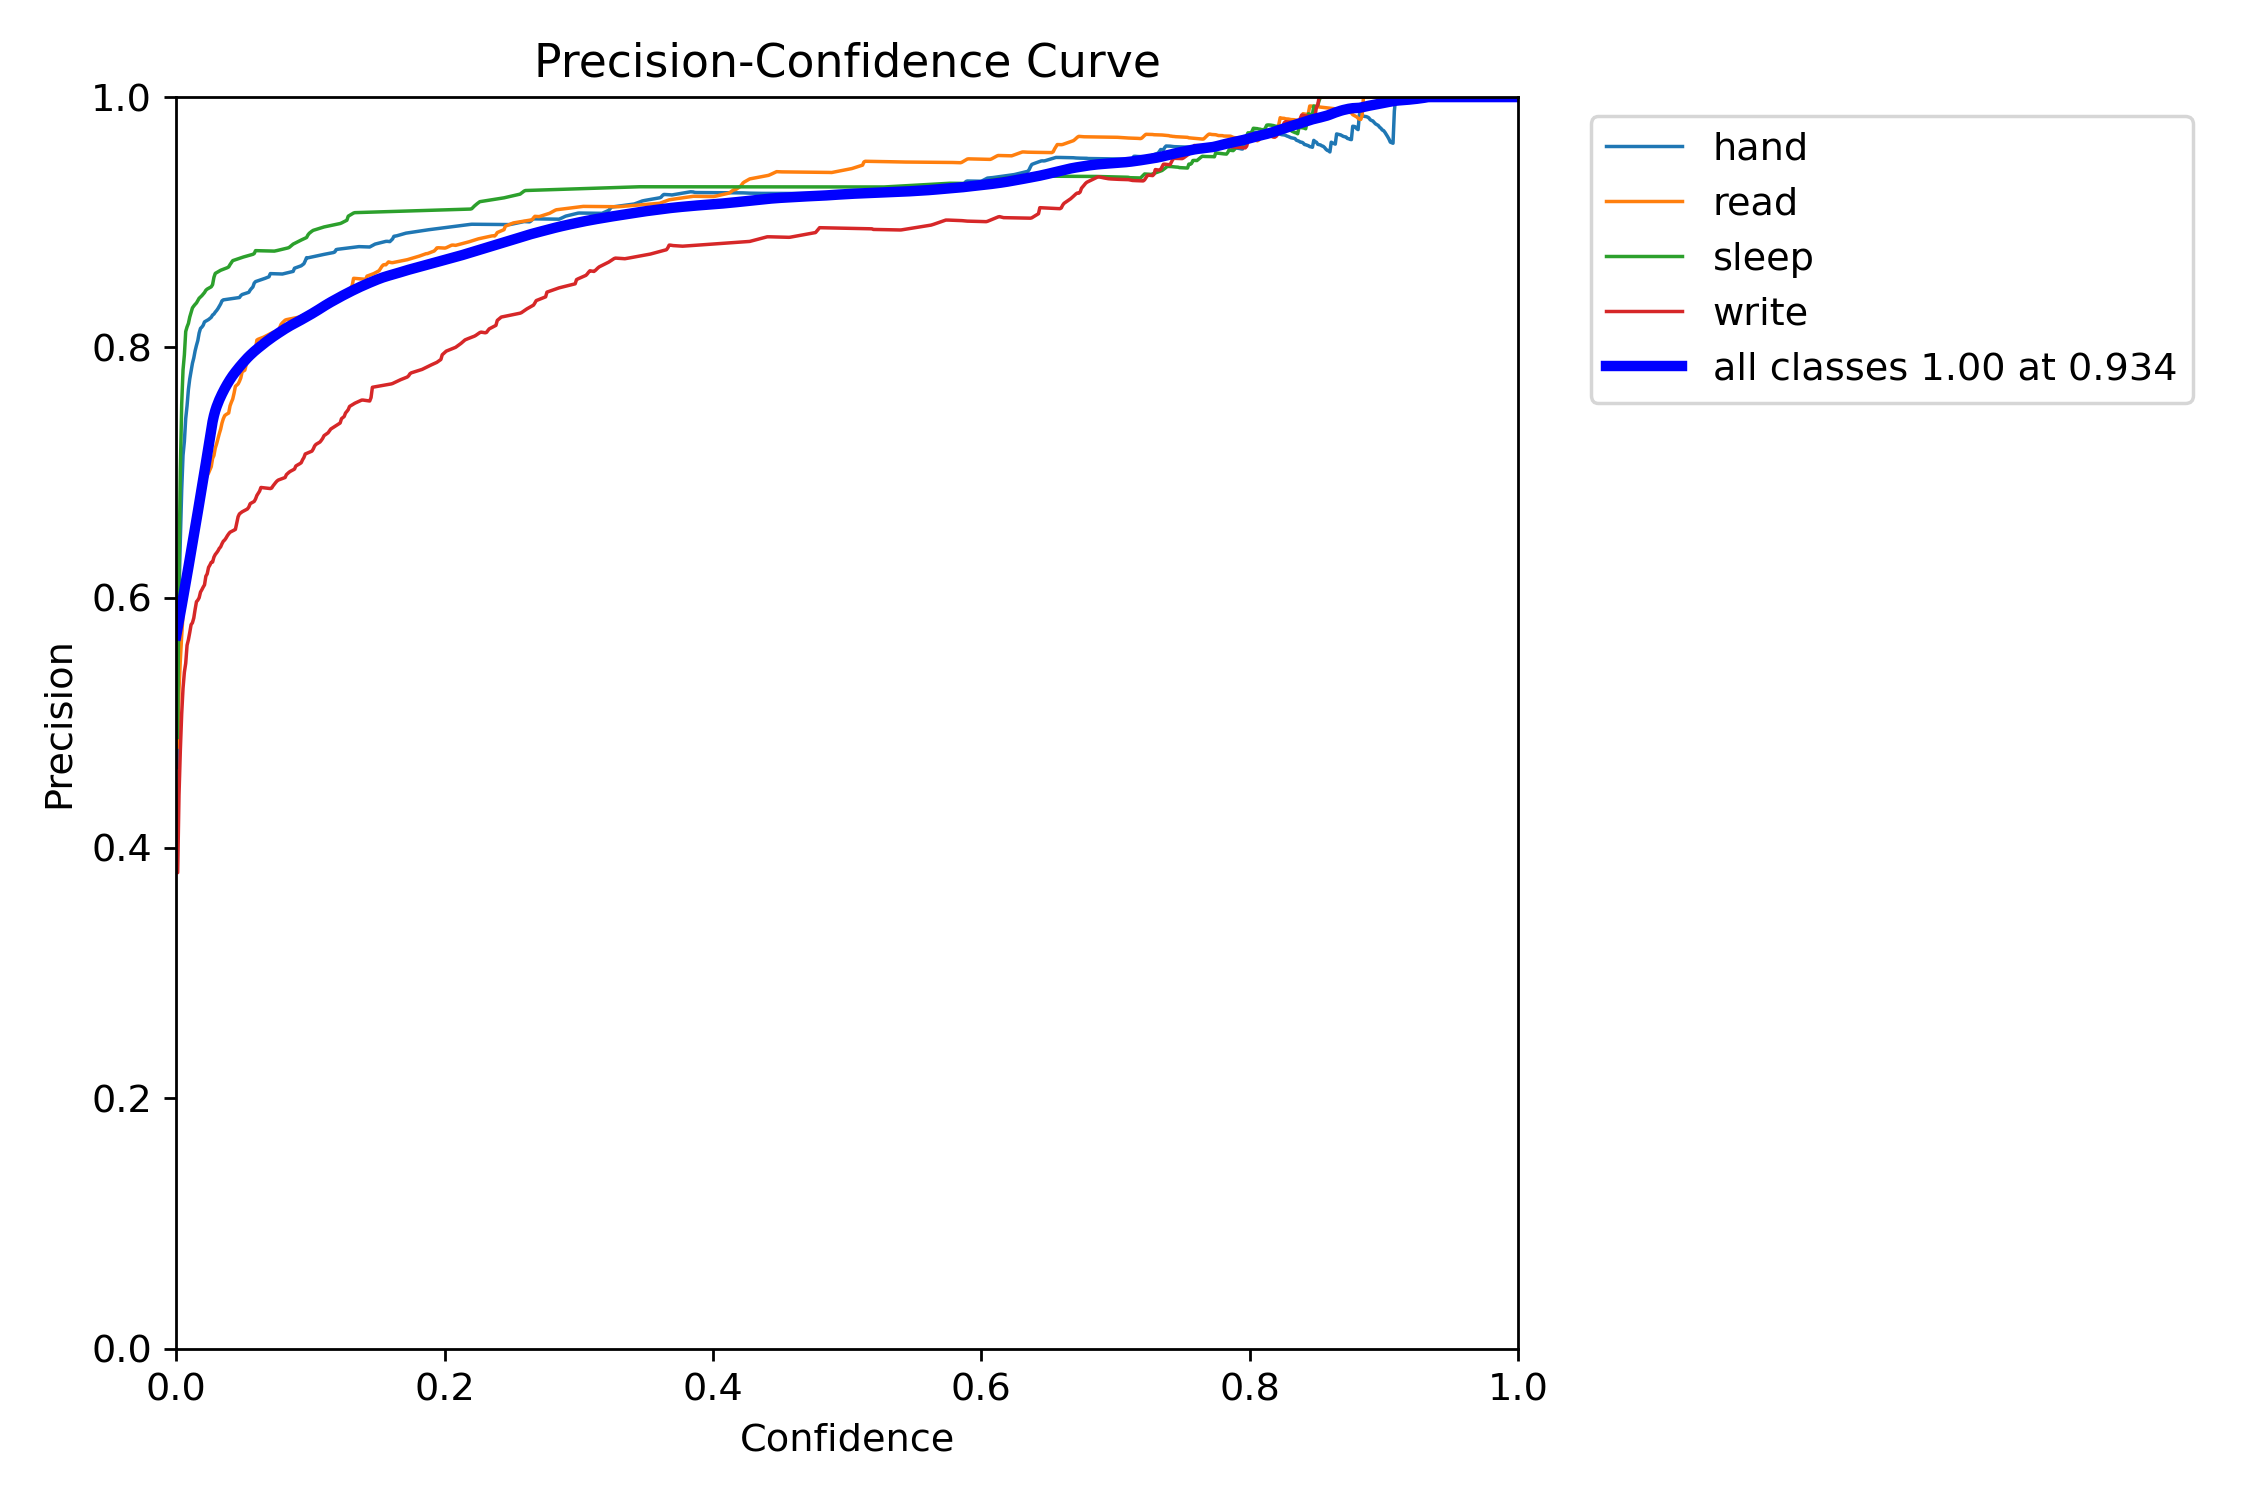

In [9]:
from IPython.display import display, Image
Image(filename='/kaggle/working/runs/detect/train/P_curve.png', height=640)

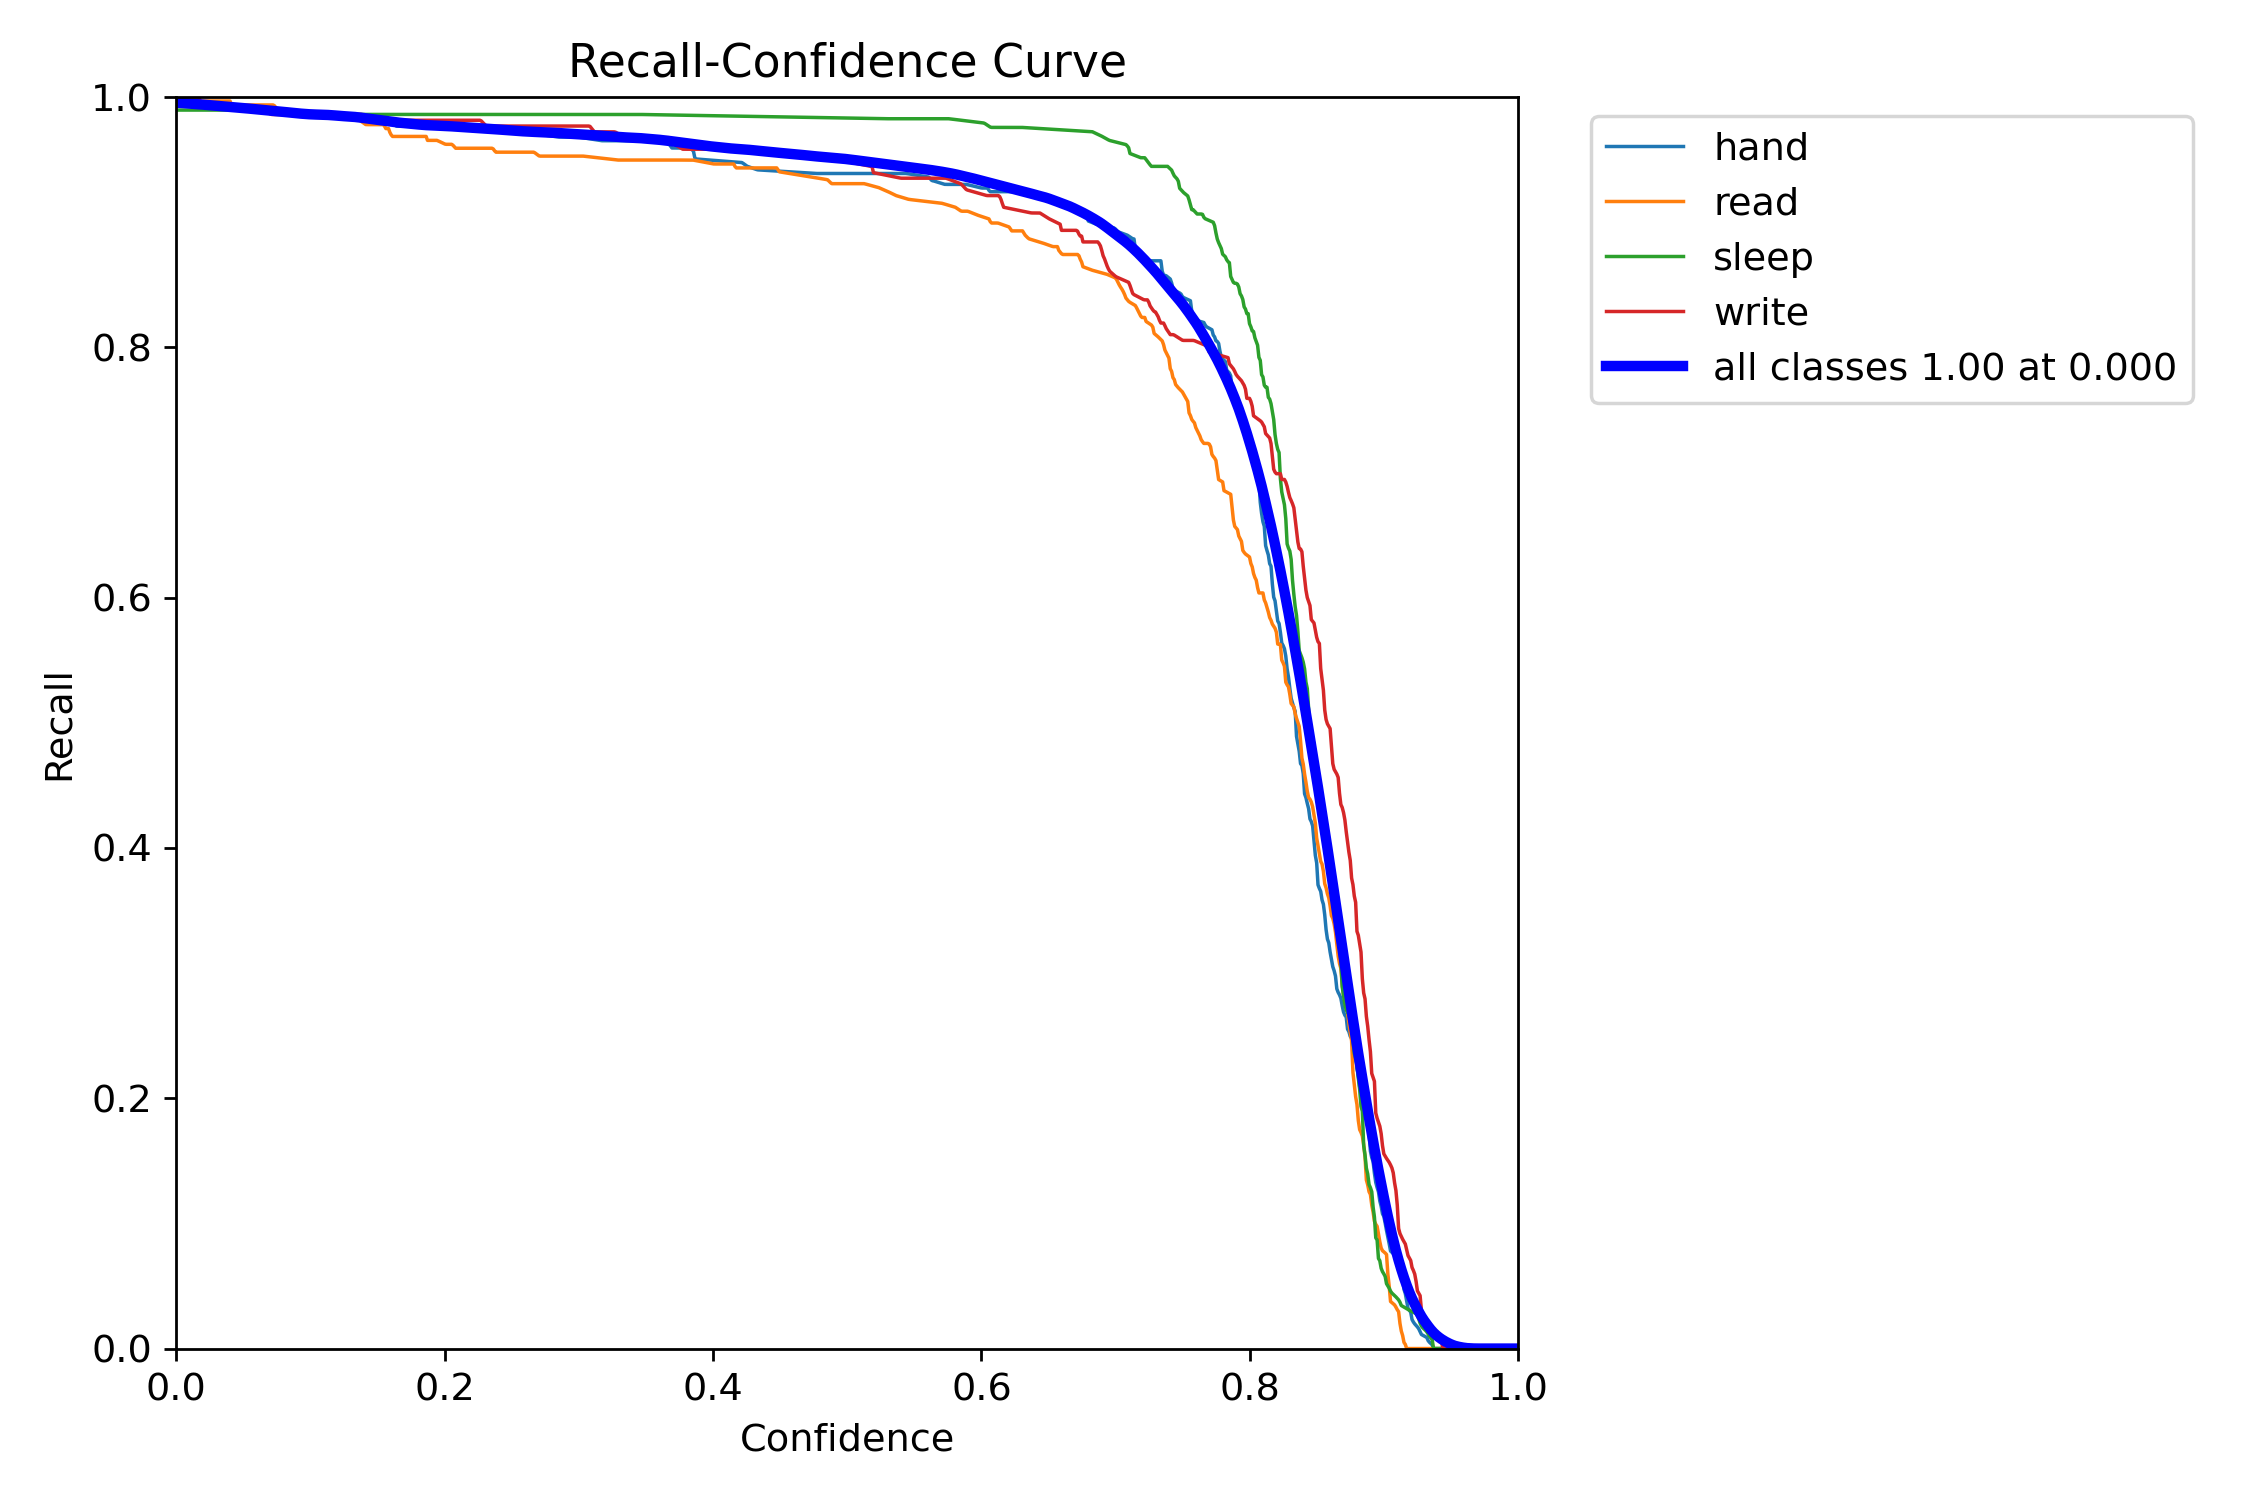

In [10]:
from IPython.display import display, Image
Image(filename='/kaggle/working/runs/detect/train/R_curve.png', height=640)

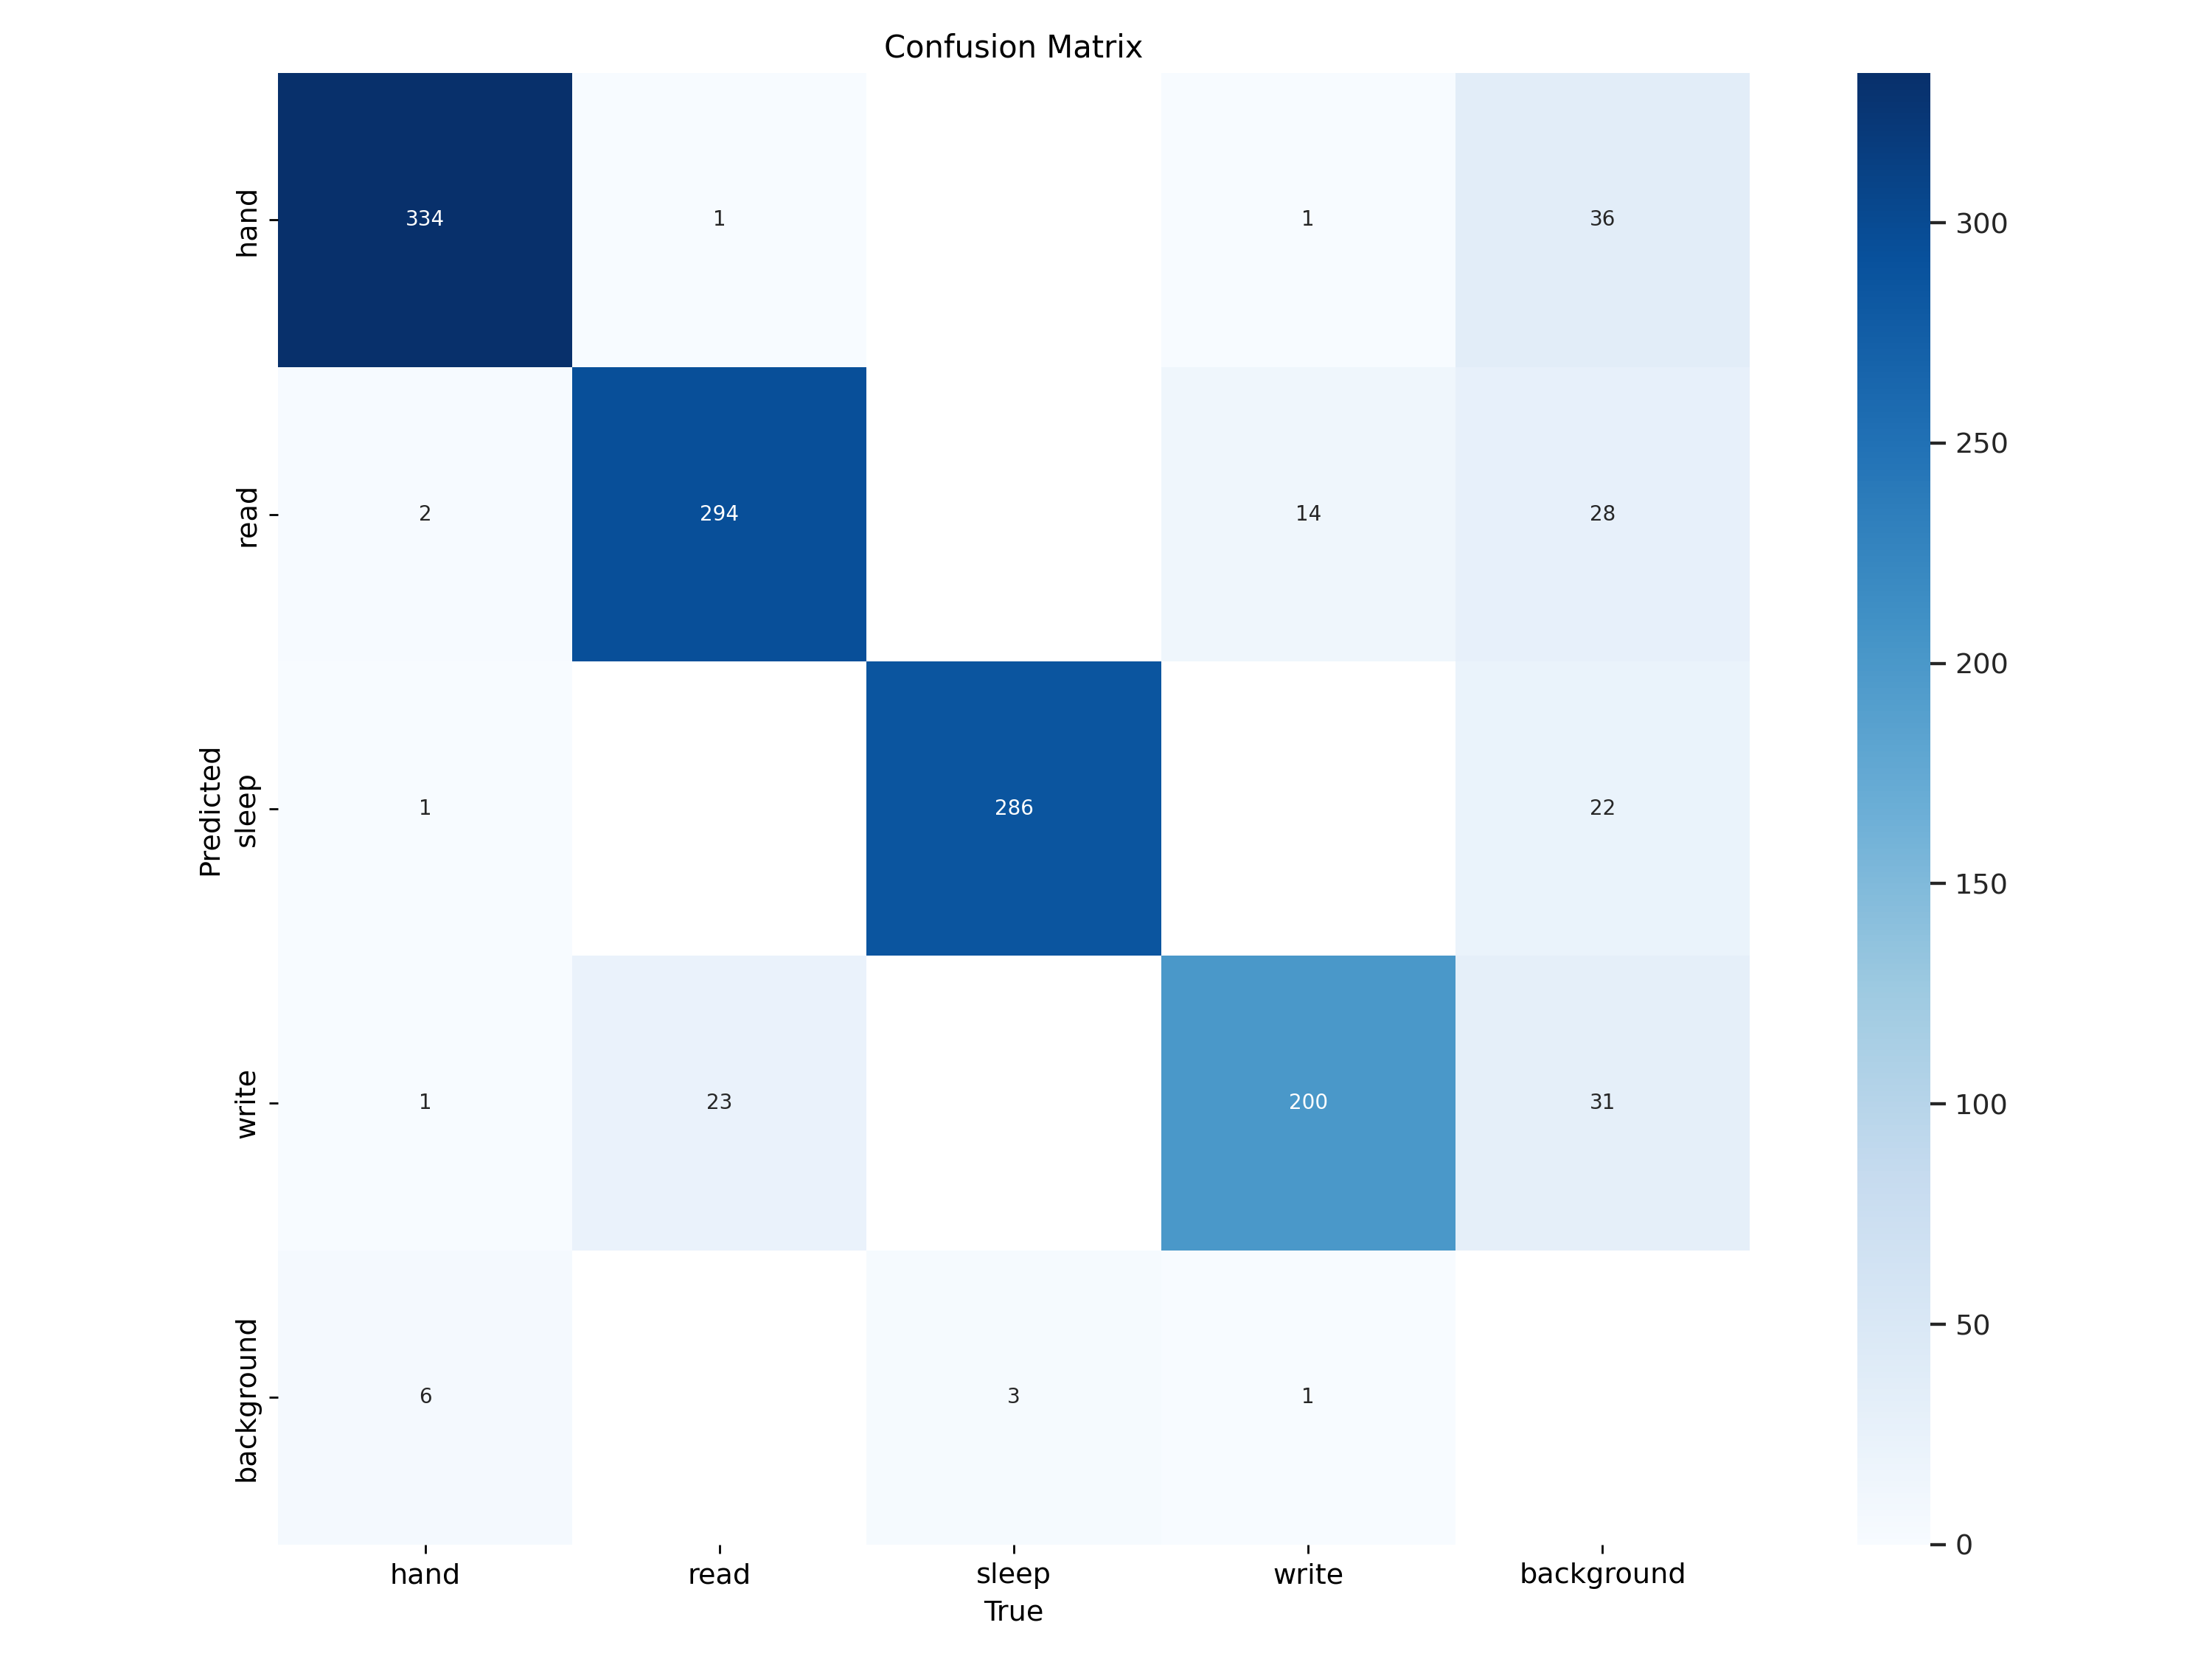

In [11]:
from IPython.display import display, Image
Image(filename='/kaggle/working/runs/detect/train/confusion_matrix.png', height=640)

# **Validation du dataset**

In [12]:
!yolo task=detect mode=val model=/kaggle/working/runs/detect/train/weights/best.pt data=/kaggle/working/classroom-24/data.yaml

Ultralytics 8.3.49 🚀 Python-3.10.14 torch-2.4.0 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Scanning /kaggle/working/classroom-24/valid/labels.cache... 425 images, 3 b
                 Class     Images  Instances      Box(P          R      mAP50  m
                   all        425       1167      0.914       0.96       0.97      0.716
                  hand        269        344      0.924      0.949      0.965      0.702
                  read        135        318      0.921      0.947      0.972       0.72
                 sleep        261        289      0.928      0.985      0.974      0.683
                 write        121        216      0.883      0.958       0.97      0.759
Speed: 1.0ms preprocess, 4.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


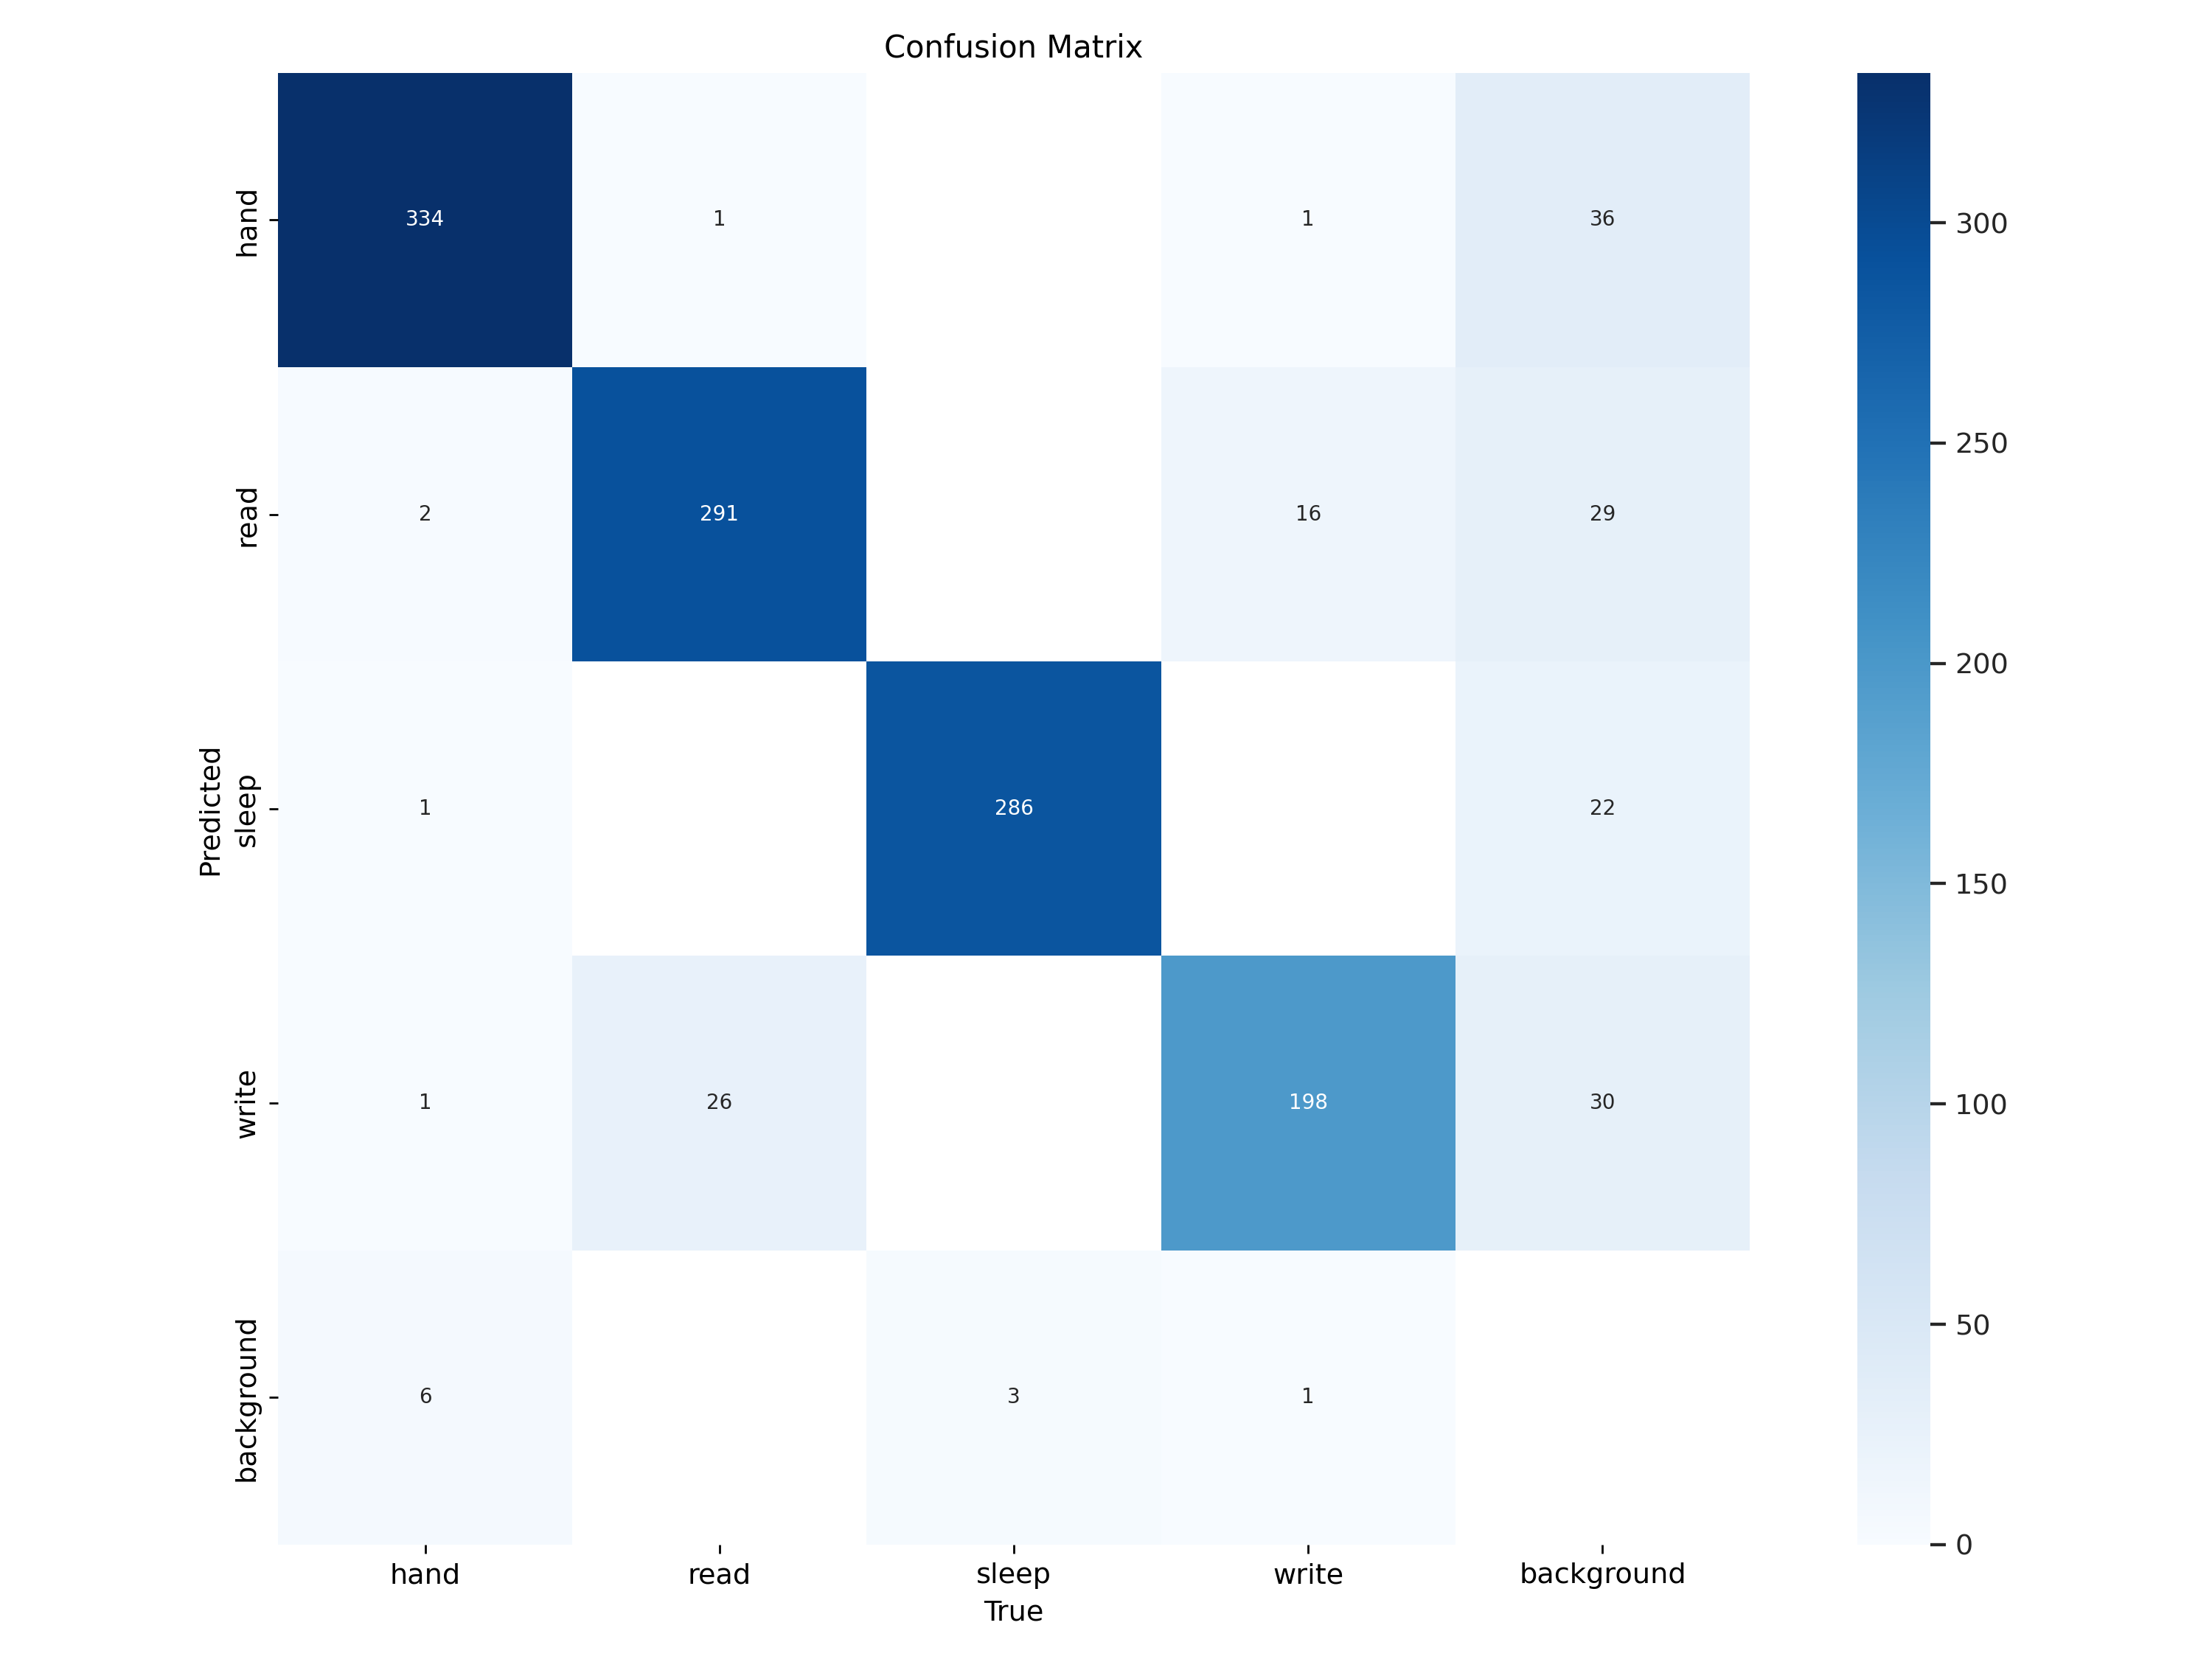

In [13]:
Image(filename='/kaggle/working/runs/detect/val/confusion_matrix.png', height=640)

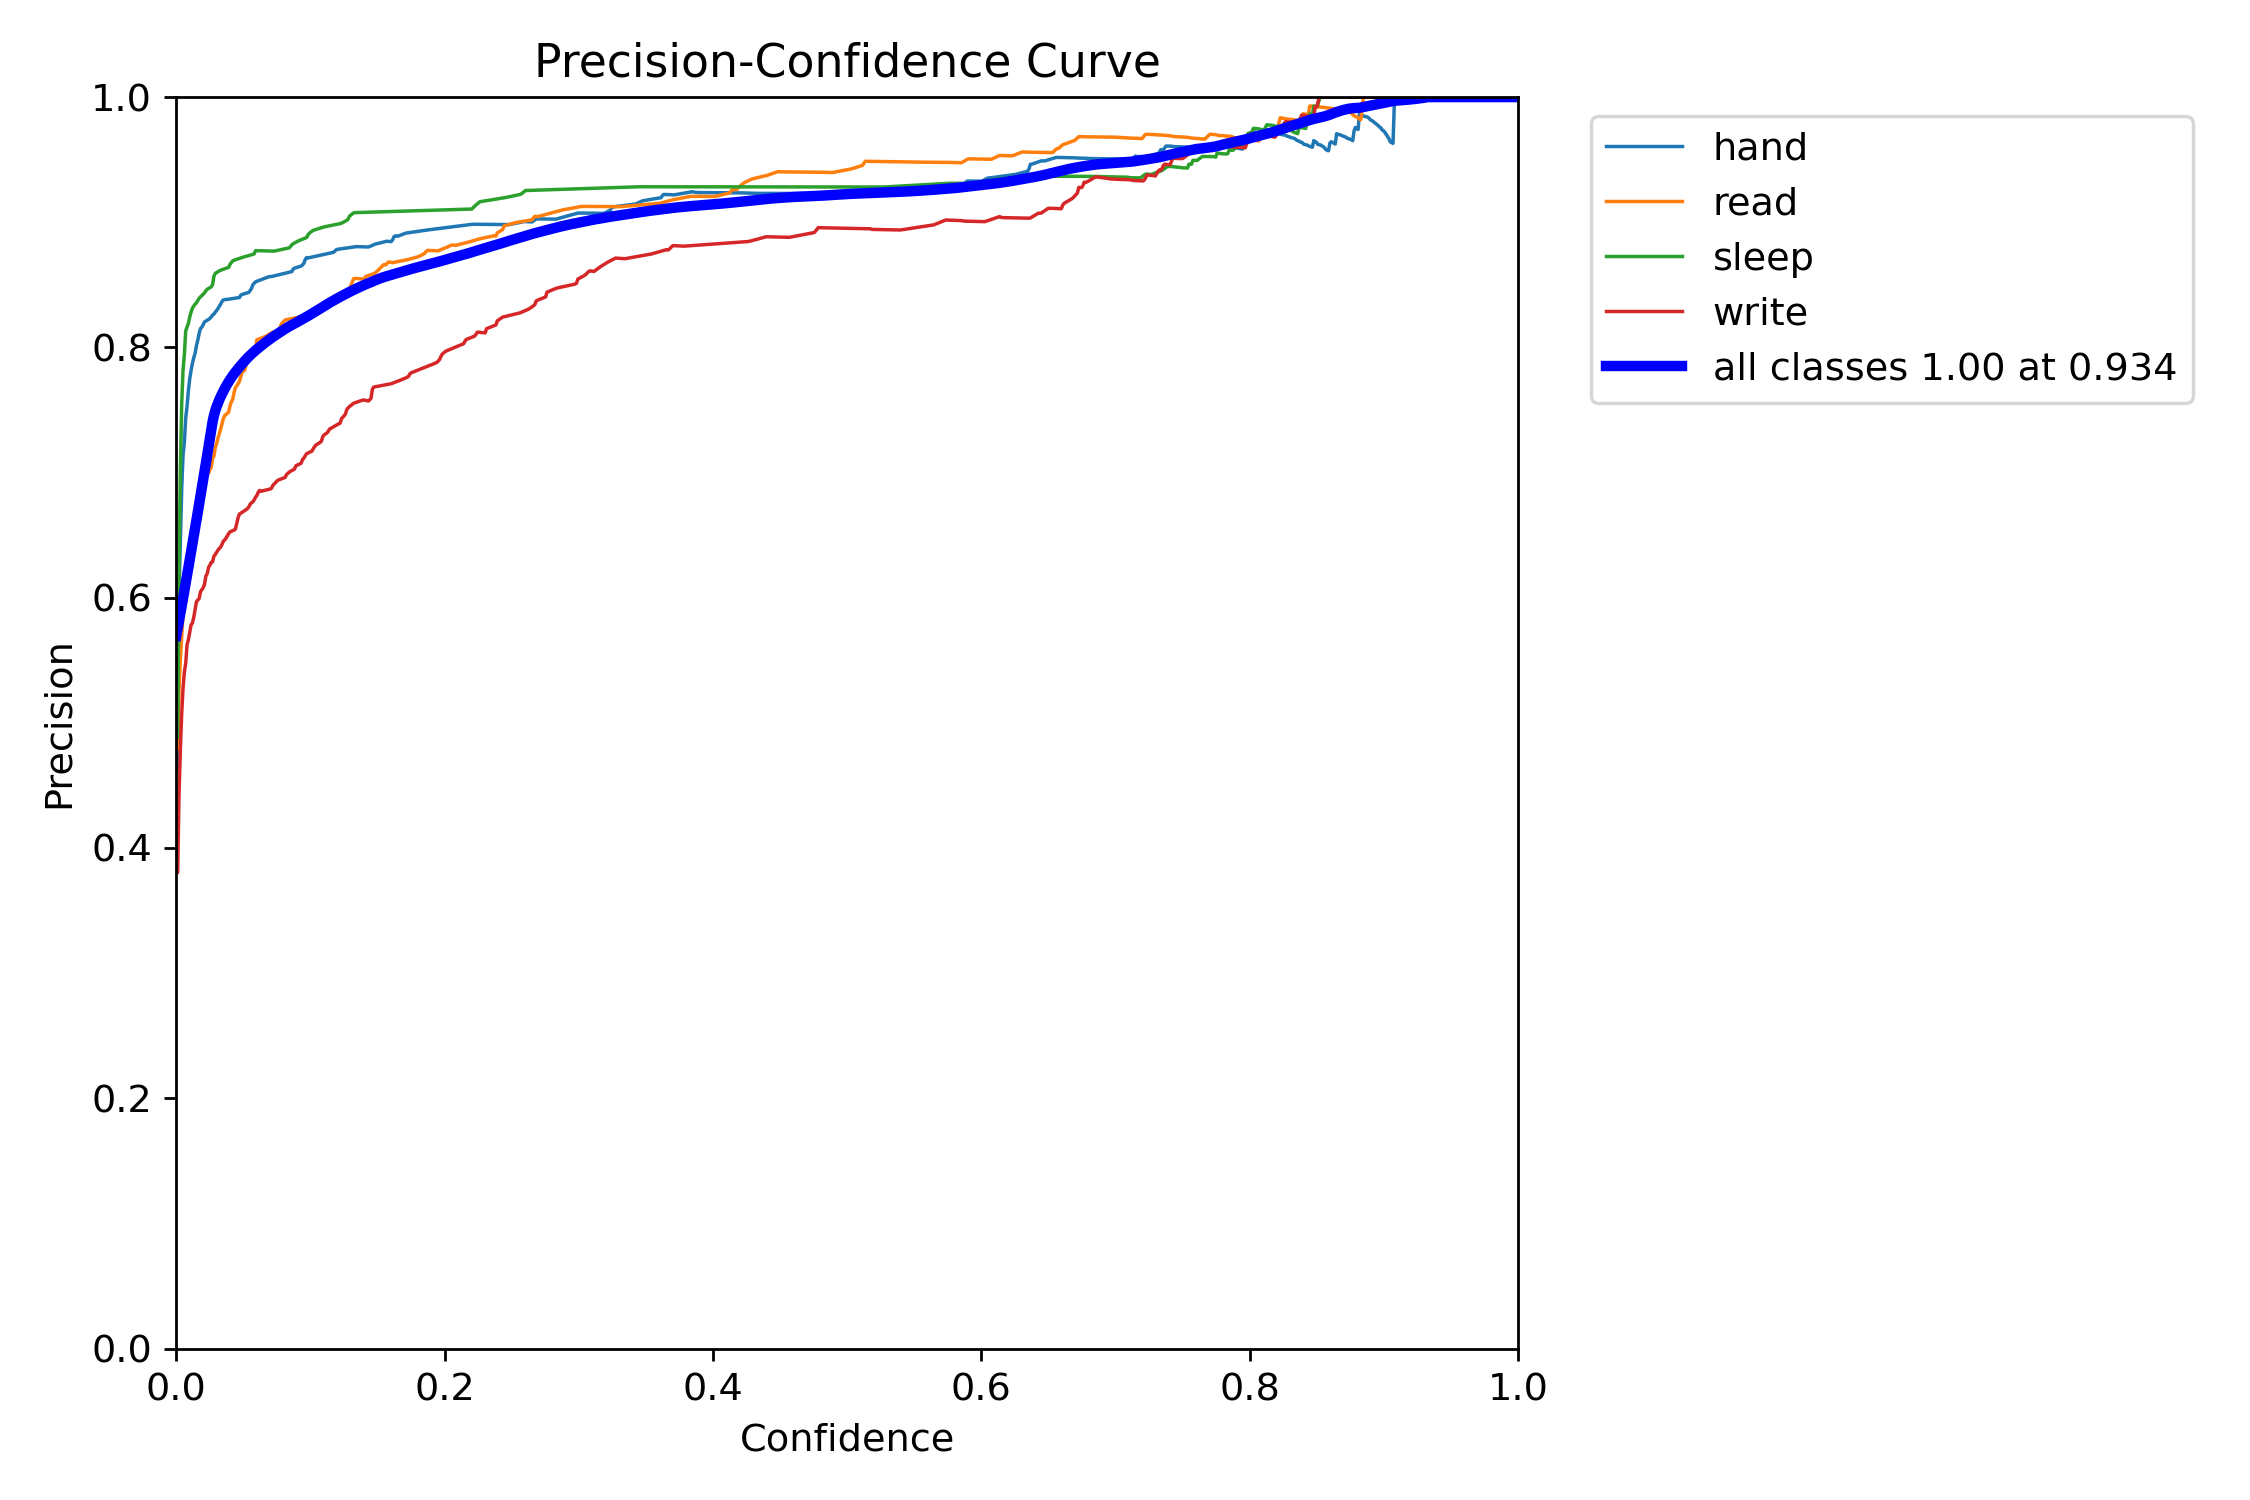

In [14]:
Image(filename='/kaggle/working/runs/detect/val/P_curve.png', height=640)

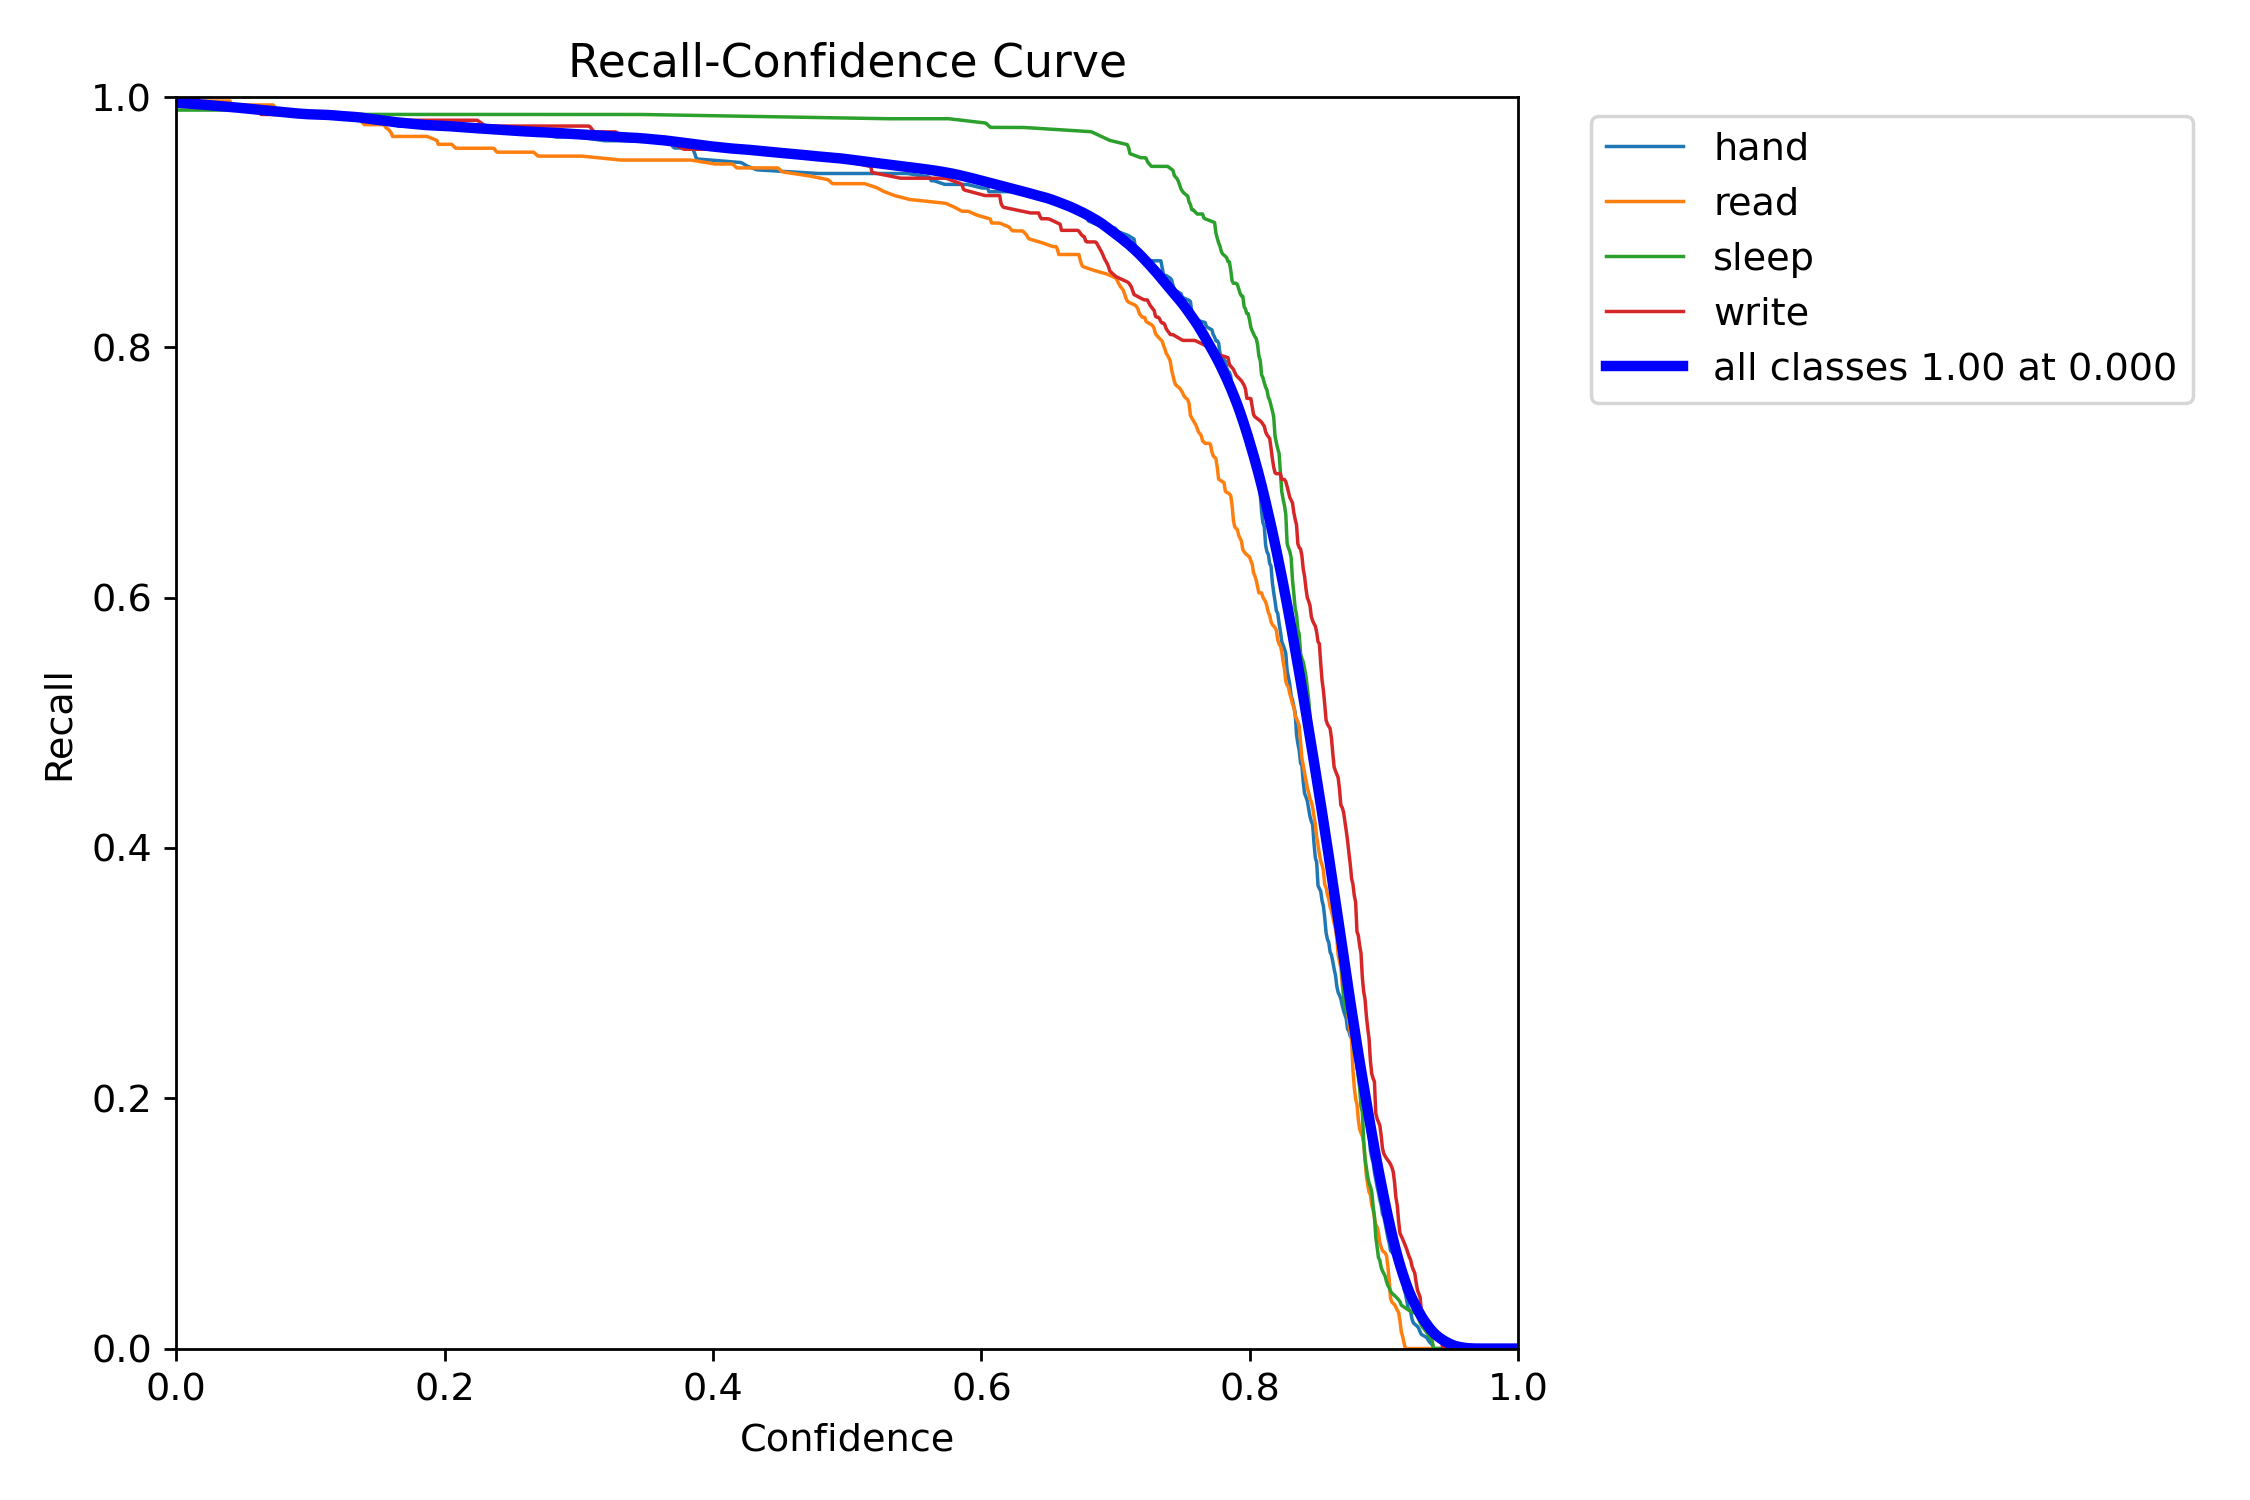

In [15]:
Image(filename='/kaggle/working/runs/detect/val/R_curve.png', height=640)

# **Prédiction des données de test**

In [16]:
!yolo task=detect mode=predict model=/kaggle/working/runs/detect/train/weights/best.pt conf=0.50 source=/kaggle/working/classroom-24/test/images

Ultralytics 8.3.49 🚀 Python-3.10.14 torch-2.4.0 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 168 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs

image 1/880 /kaggle/working/classroom-24/test/images/392_jpg.rf.1175c4336c8f3f4639d0b239e4dd36ca.jpg: 704x704 1 sleep, 8.6ms
image 2/880 /kaggle/working/classroom-24/test/images/4513_jpg.rf.a32fc7986e0ba83d24704c107fe6dfd5.jpg: 704x704 (no detections), 8.1ms
image 3/880 /kaggle/working/classroom-24/test/images/45_jpg.rf.6191e21a55c8c049a1c0f17c6cdb806a.jpg: 704x704 1 sleep, 8.0ms
image 4/880 /kaggle/working/classroom-24/test/images/501_jpg.rf.e2df3ad1f5101e82b06f0af955368aeb.jpg: 704x704 1 hand, 1 sleep, 8.0ms
image 5/880 /kaggle/working/classroom-24/test/images/IMG_2624-Trim_MOV-0_jpg.rf.8192bbb5802f8be72884f6d121ae8244.jpg: 704x704 1 hand, 1 sleep, 8.0ms
image 6/880 /kaggle/working/classroom-24/test/images/IMG_2624-Trim_MOV-102_jpg.rf.ae41c7902f6aa72e7505524f9f8ba777.jpg: 704x704 1 hand, 8.0ms
image 7/880 /kaggle/working/classro

# **Test sur quelques images du dataset**

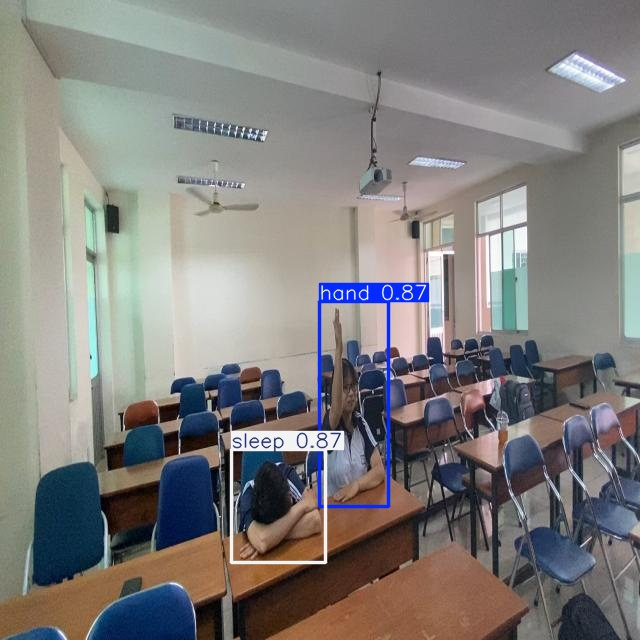

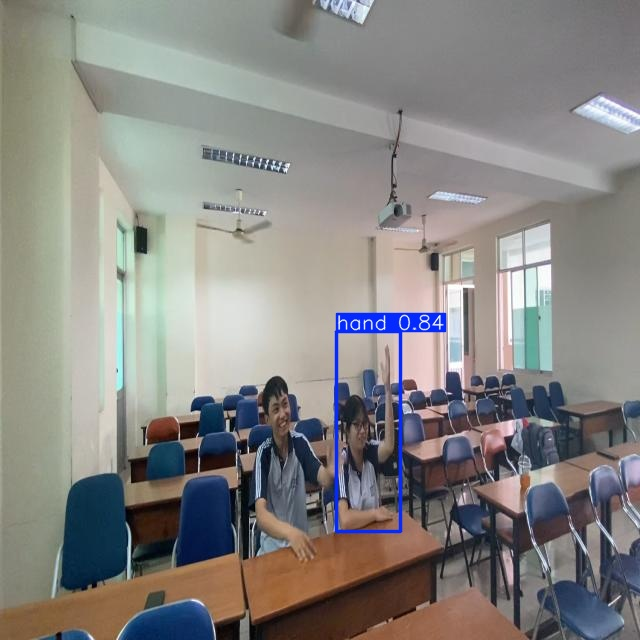

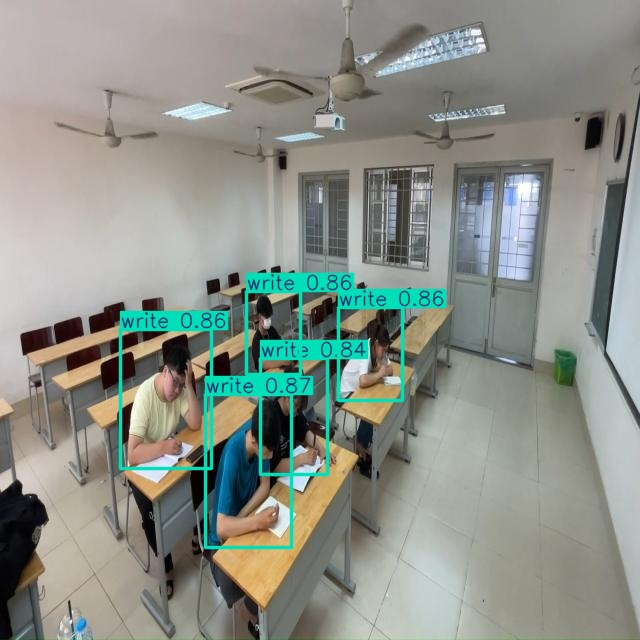

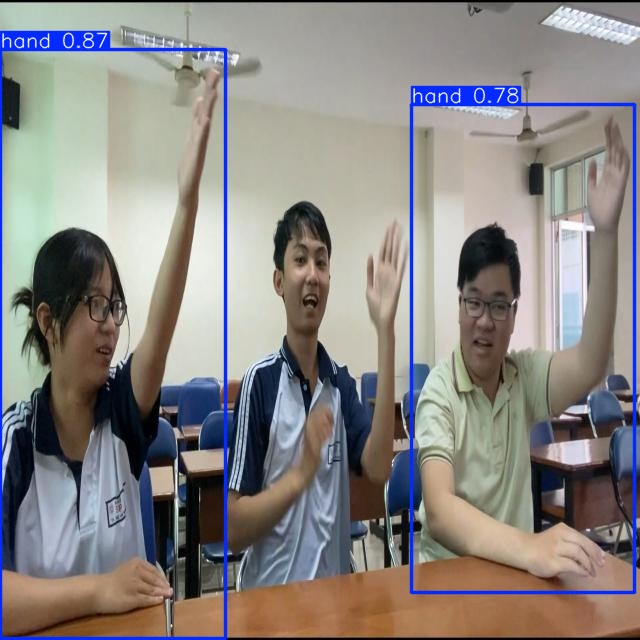

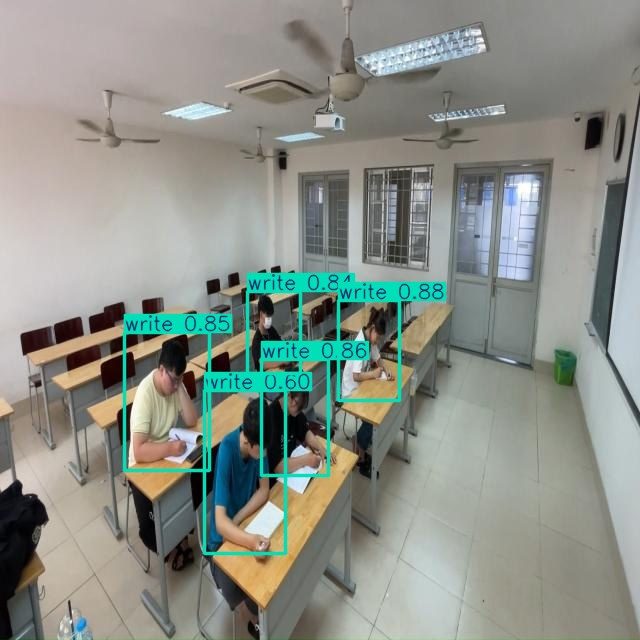

In [17]:
import glob
import os
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/kaggle/working/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:5]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")

In [18]:
!zip -r YOLOV802.zip  /kaggle/working/

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/classroom-24/ (stored 0%)
  adding: kaggle/working/classroom-24/data.yaml (deflated 35%)
  adding: kaggle/working/classroom-24/README.roboflow.txt (deflated 46%)
  adding: kaggle/working/classroom-24/test/ (stored 0%)
  adding: kaggle/working/classroom-24/test/labels/ (stored 0%)
  adding: kaggle/working/classroom-24/test/labels/IMG_2625_MOV-321_jpg.rf.26892e8eb325f8d7cffa85fb3cb2d7d4.txt (deflated 35%)
  adding: kaggle/working/classroom-24/test/labels/Thg2_2_Trim_mp4-227_jpg.rf.8176f2985b9f7664799f96d72e923534.txt (deflated 50%)
  adding: kaggle/working/classroom-24/test/labels/IMG_2624-Trim_MOV-468_jpg.rf.7540d8ad6fa76deb9c9be74e1f0bb1ae.txt (deflated 32%)
  adding: kaggle/working/classroom-24/test/labels/IMG_2624-Trim_MOV-289_jpg.rf.e636e49ddfbb940e11911847112caf75.txt (deflated 44%)
  adding: kaggle/working/classroom-24/test/labels/giua_mp4-232_jpg.rf.372c4a92c094bfc060f0712de71f409e.txt (deflated 34%)
  adding: kaggle/